<a href="https://colab.research.google.com/github/YamenObeidat/Deep-learning-part-1/blob/main/DeepLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

csv_path = (
    "Used_Car_Price_Prediction.csv"
    if os.path.exists("Used_Car_Price_Prediction.csv")
    else os.path.join("data", "Used_Car_Price_Prediction.csv")
)

df = pd.read_csv(csv_path)
print("Shape:", df.shape)
print("\nMissing values per column:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nTarget (sale_price) summary:\n", df["sale_price"].describe())
df.head(3)

Using device: cpu
Shape: (7400, 29)

Missing values per column:
 body_type               103
transmission            556
registered_city          10
registered_state         10
source                  126
car_availability        620
original_price         3280
car_rating                9
ad_created_on             1
fitness_certificate       8
dtype: int64

Target (sale_price) summary:
 count       7,400.00
mean      454,889.19
std       282,702.33
min             0.00
25%       281,174.00
50%       382,449.00
75%       540,149.00
max     3,866,000.00
Name: sale_price, dtype: float64


,car_name,yr_mfr,fuel_type,kms_run,sale_price,city,times_viewed,body_type,transmission,variant,...,total_owners,broker_quote,original_price,car_rating,ad_created_on,fitness_certificate,emi_starts_from,booking_down_pymnt,reserved,warranty_avail
0,maruti swift,2015,petrol,8063,386399,noida,18715,hatchback,manual,lxi opt,...,2,397677,"404,177.00",great,2021-04-04T07:09:18.583,True,8975,57960,False,False
1,maruti alto 800,2016,petrol,23104,265499,noida,2676,hatchback,manual,lxi,...,1,272935,"354,313.00",great,2021-03-22T14:07:32.833,True,6167,39825,False,False
2,hyundai grand i10,2017,petrol,23402,477699,noida,609,hatchback,manual,sports 1.2 vtvt,...,1,469605,NaN,great,2021-03-20T05:36:31.311,True,11096,71655,False,False


In [7]:

df_clean = df.drop_duplicates().copy()
df_clean = df_clean[df_clean["sale_price"].notna() & (df_clean["sale_price"] > 0)].copy()
print("Rows after cleaning:", len(df_clean))  # Must be between 1,000 and 200,000

target_col = "sale_price"


cols_to_drop = [
    target_col,
    "broker_quote",
    "emi_starts_from",
    "booking_down_pymnt",
    "car_name",
    "variant",
    "rto",
    "registered_city",
    "ad_created_on",
]

X_df = df_clean.drop(columns=cols_to_drop).copy()
y = df_clean[target_col].to_numpy(dtype=np.float32).reshape(-1, 1)


num_cols = X_df.select_dtypes(include=["int64", "float64", "bool"]).columns.tolist()
cat_cols = [c for c in X_df.columns if c not in num_cols]

for col in X_df.select_dtypes(include=["bool"]).columns:
    X_df[col] = X_df[col].astype(np.float32)

X_train_df, X_temp_df, y_train, y_temp = train_test_split(
    X_df, y, test_size=0.30, random_state=42
)
X_val_df, X_test_df, y_val, y_test = train_test_split(
    X_temp_df, y_temp, test_size=0.50, random_state=42
)

num_imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_num = scaler.fit_transform(num_imputer.fit_transform(X_train_df[num_cols]))
X_val_num = scaler.transform(num_imputer.transform(X_val_df[num_cols]))
X_test_num = scaler.transform(num_imputer.transform(X_test_df[num_cols]))

cat_imputer = SimpleImputer(strategy="most_frequent")
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

X_train_cat = encoder.fit_transform(cat_imputer.fit_transform(X_train_df[cat_cols]))
X_val_cat = encoder.transform(cat_imputer.transform(X_val_df[cat_cols]))
X_test_cat = encoder.transform(cat_imputer.transform(X_test_df[cat_cols]))

X_train = np.hstack([X_train_num, X_train_cat]).astype(np.float32)
X_val = np.hstack([X_val_num, X_val_cat]).astype(np.float32)
X_test = np.hstack([X_test_num, X_test_cat]).astype(np.float32)

print("Train shape:", X_train.shape, y_train.shape)
print("Val shape:  ", X_val.shape, y_val.shape)
print("Test shape: ", X_test.shape, y_test.shape)

X_train_t = torch.tensor(X_train)
y_train_t = torch.tensor(y_train)
X_val_t = torch.tensor(X_val)
y_val_t = torch.tensor(y_val)

Rows after cleaning: 7396
Train shape: (5177, 264) (5177, 1)
Val shape:   (1109, 264) (1109, 1)
Test shape:  (1110, 264) (1110, 1)


In [8]:

y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train).astype(np.float32)
y_val_scaled = y_scaler.transform(y_val).astype(np.float32)

train_loader = DataLoader(
    TensorDataset(torch.tensor(X_train), torch.tensor(y_train_scaled)),
    batch_size=64,
    shuffle=True,
)

def make_mlp(input_dim, hidden_dims):
    """Build a feed-forward network with ReLU activations.
    An empty list [] gives plain linear regression (no hidden layers).
    """
    layers = []
    prev_dim = input_dim
    for h in hidden_dims:
        layers.append(nn.Linear(prev_dim, h))
        layers.append(nn.ReLU())
        prev_dim = h
    layers.append(nn.Linear(prev_dim, 1))
    return nn.Sequential(*layers)

def mse_original_scale(model, X_np, y_true_orig):
    """Compute MSE in original sale_price units (INR)."""
    model.eval()
    with torch.no_grad():
        pred_scaled = model(torch.tensor(X_np)).numpy()
        pred_orig = y_scaler.inverse_transform(pred_scaled)
    return float(np.mean((y_true_orig - pred_orig) ** 2))

def train_model(model, optimizer, criterion, epochs=30):
    """Train for a fixed number of epochs and return train/val MSE per epoch + elapsed time."""
    train_mses, val_mses = [], []
    start = time.time()

    for _ in range(epochs):
        model.train()
        for bx, by in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()

        train_mses.append(mse_original_scale(model, X_train, y_train))
        val_mses.append(mse_original_scale(model, X_val, y_val))

    elapsed = time.time() - start
    return train_mses, val_mses, elapsed

input_dim = X_train.shape[1]
criterion = nn.MSELoss()
EPOCHS = 30

torch.manual_seed(42)
lin_model = make_mlp(input_dim, hidden_dims=[])
lin_opt = torch.optim.SGD(lin_model.parameters(), lr=0.01)
lin_train_mse, lin_val_mse, lin_time = train_model(lin_model, lin_opt, criterion, epochs=EPOCHS)

torch.manual_seed(42)
nn_model = make_mlp(input_dim, hidden_dims=[64, 64, 64])
nn_opt = torch.optim.Adam(nn_model.parameters(), lr=0.003)
nn_train_mse, nn_val_mse, nn_time = train_model(nn_model, nn_opt, criterion, epochs=EPOCHS)

print(f"Linear Regression -> Train MSE: {lin_train_mse[-1]:,.0f} | Val MSE: {lin_val_mse[-1]:,.0f} | Time: {lin_time:.2f}s")
print(f"Baseline NN [64x3]-> Train MSE: {nn_train_mse[-1]:,.0f} | Val MSE: {nn_val_mse[-1]:,.0f} | Time: {nn_time:.2f}s")

Linear Regression -> Train MSE: 16,870,088,704 | Val MSE: 14,457,911,296 | Time: 2.32s
Baseline NN [64x3]-> Train MSE: 794,033,024 | Val MSE: 4,787,180,544 | Time: 5.40s


In [11]:


EXP_EPOCHS = 20
input_dim = X_train.shape[1]

def get_optimizer(name, params, lr):
    if name == "sgd":
        return torch.optim.SGD(params, lr=lr)
    if name == "momentum":
        return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if name == "adam":
        return torch.optim.Adam(params, lr=lr)
    raise ValueError(f"Unknown optimizer: {name}")

def get_loss(name):
    if name == "mse":
        return nn.MSELoss()
    if name == "l1":
        return nn.L1Loss()
    if name == "huber":
        return nn.HuberLoss()
    raise ValueError(f"Unknown loss: {name}")

def run_experiment(
    run_id,
    topic,
    setting_label,
    hidden_dims=[64, 64, 64],
    opt_name="adam",
    lr=0.003,
    batch_size=64,
    loss_name="mse",
    epochs=EXP_EPOCHS,
):
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    loader = DataLoader(
        TensorDataset(torch.tensor(X_train), torch.tensor(y_train_scaled)),
        batch_size=batch_size,
        shuffle=True,
    )
    model = make_mlp(input_dim, hidden_dims).to(device)
    optimizer = get_optimizer(opt_name, model.parameters(), lr)
    criterion = get_loss(loss_name)

    start_t = time.time()
    diverged = False

    for _ in range(epochs):
        model.train()
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            if not torch.isfinite(loss):
                diverged = True
                break
            loss.backward()
            optimizer.step()
        if diverged:
            break

    elapsed = round(time.time() - start_t, 2)
    train_mse = float("nan") if diverged else mse_original_scale(model.cpu(), X_train, y_train)
    val_mse = float("nan") if diverged else mse_original_scale(model.cpu(), X_val, y_val)

    return {
        "Run": run_id,
        "Topic": topic,
        "Setting": setting_label,
        "Train MSE": train_mse,
        "Val MSE": val_mse,
        "Time (s)": elapsed,
    }

experiments = [
    # Baseline (Run 1)
    run_experiment(1, "Baseline NN", "Ref NN: [64,64,64], Adam, lr=0.003, bs=64, MSE"),


    run_experiment(2, "Learning rate", "lr = 0.0001", lr=0.0001),
    run_experiment(3, "Learning rate", "lr = 0.0005", lr=0.0005),
    run_experiment(4, "Learning rate", "lr = 0.001", lr=0.001),
    run_experiment(5, "Learning rate", "lr = 0.01", lr=0.01),
    run_experiment(6, "Learning rate", "lr = 0.05", lr=0.05),
    run_experiment(7, "Learning rate", "lr = 0.5", lr=0.5),


    run_experiment(8, "Optimizer", "SGD (lr=0.003)", opt_name="sgd", lr=0.003),
    run_experiment(9, "Optimizer", "SGD + momentum 0.9 (lr=0.003)", opt_name="momentum", lr=0.003),
    run_experiment(10, "Optimizer", "Adam (lr=0.003)", opt_name="adam", lr=0.003),
    run_experiment(11, "Optimizer", "SGD (lr=0.003, 10 epochs)", opt_name="sgd", lr=0.003, epochs=10),
    run_experiment(12, "Optimizer", "Momentum 0.9 (lr=0.003, 10 epochs)", opt_name="momentum", lr=0.003, epochs=10),
    run_experiment(13, "Optimizer", "Adam (lr=0.003, 10 epochs)", opt_name="adam", lr=0.003, epochs=10),


    run_experiment(14, "Batch size", "batch_size = 8", batch_size=8),
    run_experiment(15, "Batch size", "batch_size = 16", batch_size=16),
    run_experiment(16, "Batch size", "batch_size = 32", batch_size=32),
    run_experiment(17, "Batch size", "batch_size = 128", batch_size=128),
    run_experiment(18, "Batch size", "batch_size = 256", batch_size=256),
    run_experiment(19, "Batch size", "batch_size = 512", batch_size=512),


    run_experiment(20, "Depth and width", "hidden = [32]", hidden_dims=[32]),
    run_experiment(21, "Depth and width", "hidden = [64]", hidden_dims=[64]),
    run_experiment(22, "Depth and width", "hidden = [128]", hidden_dims=[128]),
    run_experiment(23, "Depth and width", "hidden = [32, 32]", hidden_dims=[32, 32]),
    run_experiment(24, "Depth and width", "hidden = [128, 128]", hidden_dims=[128, 128]),
    run_experiment(25, "Depth and width", "hidden = [128, 128, 128]", hidden_dims=[128, 128, 128]),
    run_experiment(26, "Depth and width", "hidden = [64, 64, 64, 64]", hidden_dims=[64, 64, 64, 64]),

    # Topic 5: Loss function (6 runs, keeping lr=0.003 & opt='adam' so only loss_name changes)
    run_experiment(27, "Loss function", "L1Loss (lr=0.003)", loss_name="l1", lr=0.003),
    run_experiment(28, "Loss function", "HuberLoss (lr=0.003)", loss_name="huber", lr=0.003),
    run_experiment(29, "Loss function", "MSELoss (lr=0.003)", loss_name="mse", lr=0.003),
    run_experiment(30, "Loss function", "L1Loss (lr=0.003, 15 epochs)", loss_name="l1", lr=0.003, epochs=15),
    run_experiment(31, "Loss function", "HuberLoss (lr=0.003, 15 epochs)", loss_name="huber", lr=0.003, epochs=15),
    run_experiment(32, "Loss function", "MSELoss (lr=0.003, 15 epochs)", loss_name="mse", lr=0.003, epochs=15),
]

results_df = pd.DataFrame(experiments)
print(results_df.to_string(index=False))

 Run           Topic                                        Setting         Train MSE               Val MSE  Time (s)
   1     Baseline NN Ref NN: [64,64,64], Adam, lr=0.003, bs=64, MSE  1,186,520,704.00      4,523,015,168.00      6.92
   2   Learning rate                                    lr = 0.0001  4,918,449,152.00      5,999,085,568.00      5.36
   3   Learning rate                                    lr = 0.0005    983,809,472.00      4,267,267,072.00      2.98
   4   Learning rate                                     lr = 0.001    801,091,200.00      4,525,429,760.00      3.00
   5   Learning rate                                      lr = 0.01  2,123,804,672.00      7,953,601,024.00      3.51
   6   Learning rate                                      lr = 0.05  5,195,725,312.00      9,777,635,328.00      4.14
   7   Learning rate                                       lr = 0.5 81,998,544,896.00 60,987,067,596,800.00      3.47
   8       Optimizer                                 SGD

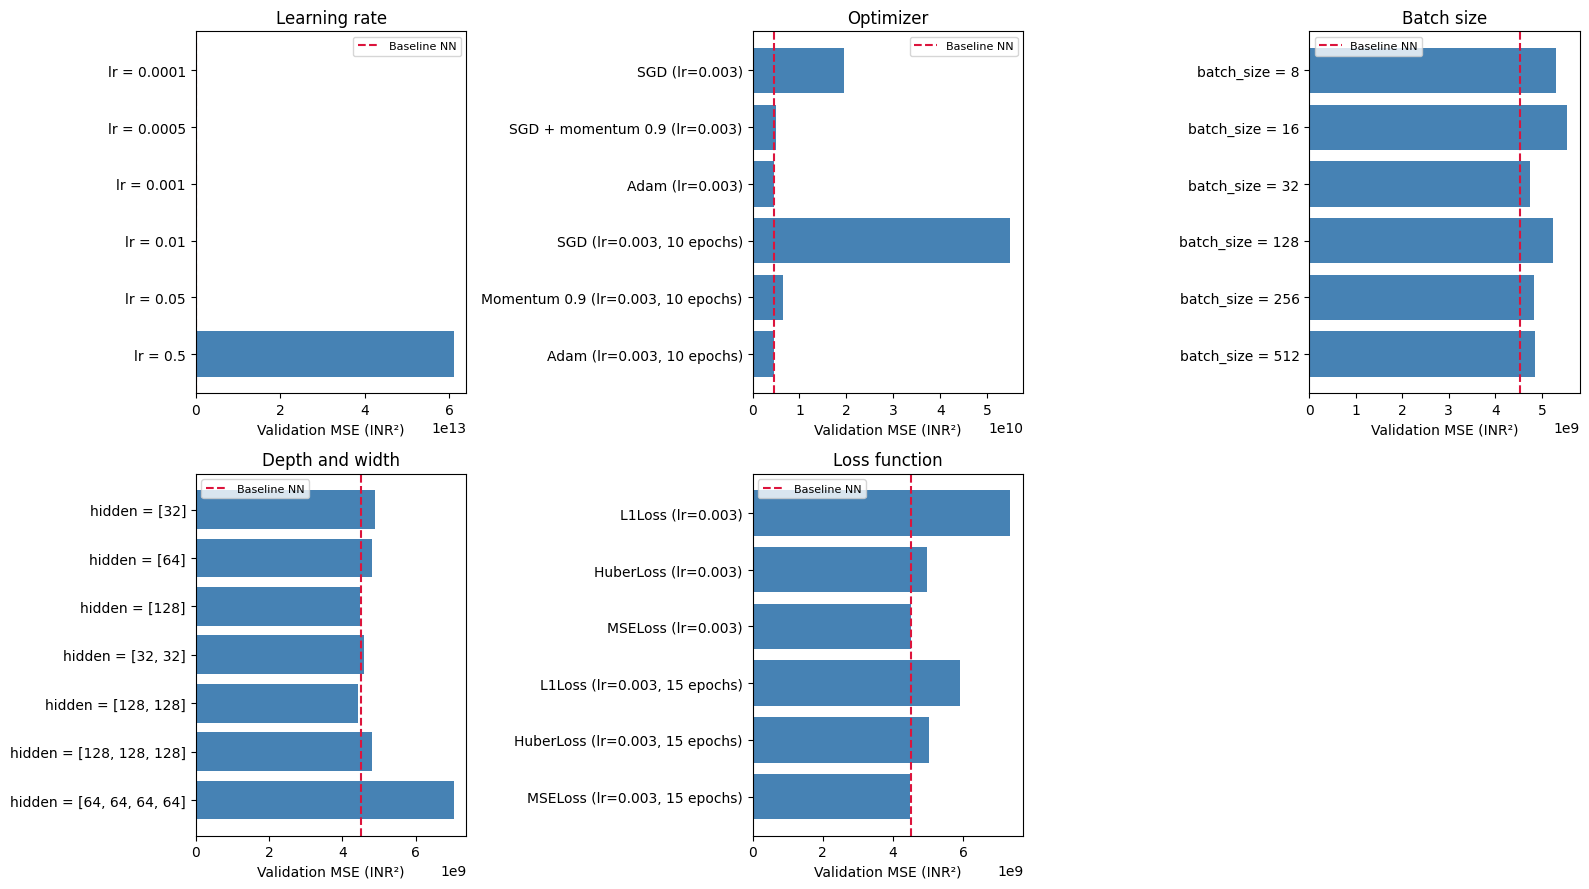

Top 5 Experiments by Validation MSE:
 Run           Topic                       Setting        Train MSE          Val MSE  Time (s)
   3   Learning rate                   lr = 0.0005   983,809,472.00 4,267,267,072.00      2.98
  24 Depth and width           hidden = [128, 128]   778,410,880.00 4,439,500,800.00      4.42
  22 Depth and width                hidden = [128]   995,115,456.00 4,482,420,736.00      2.75
  13       Optimizer    Adam (lr=0.003, 10 epochs) 1,220,081,664.00 4,483,081,728.00      1.50
  32   Loss function MSELoss (lr=0.003, 15 epochs)   901,564,736.00 4,495,953,920.00      2.86

Selected Best Run: Run 3 -> lr = 0.0005

=== Final Model Test Performance (Best Val MSE: 3,896,982,016) ===
Test MSE : 2,606,270,464
Test RMSE: 51,051.65 INR
Test MAE : 31,272.42 INR
Test R²  : 0.9556


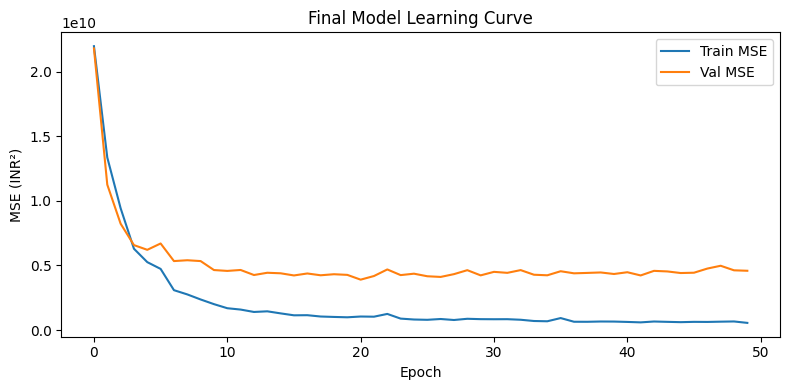

In [12]:
import copy
from sklearn.metrics import mean_absolute_error, r2_score

# --- 1. Plot Validation MSE across each experiment topic ---
topics = [t for t in results_df["Topic"].unique() if t != "Baseline NN"]
baseline_val = results_df.loc[results_df["Topic"] == "Baseline NN", "Val MSE"].values[0]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, topic in enumerate(topics):
    ax = axes[idx]
    sub = results_df[results_df["Topic"] == topic].dropna(subset=["Val MSE"])
    ax.barh(sub["Setting"], sub["Val MSE"], color="steelblue")
    ax.axvline(baseline_val, color="crimson", linestyle="--", label="Baseline NN")
    ax.set_title(topic)
    ax.set_xlabel("Validation MSE (INR²)")
    ax.invert_yaxis()
    ax.legend(fontsize=8)

# Hide unused subplot slot
for j in range(len(topics), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

# --- 2. Show Top 5 Configurations by Validation MSE ---
valid_results = results_df.dropna(subset=["Val MSE"]).sort_values("Val MSE")
print("Top 5 Experiments by Validation MSE:")
print(valid_results.head(5).to_string(index=False))

# --- 3. Train Best Model with Checkpoint Saving & Final Test Evaluation ---
# Update these settings if you want to combine your best individual findings,
# or keep the exact best run from valid_results:
best_row = valid_results.iloc[0]
print(f"\nSelected Best Run: Run {best_row['Run']} -> {best_row['Setting']}")

# Map best_row back to hyperparameters (edit if testing a combined final model)
BEST_HIDDEN = [64, 64, 64]
BEST_OPT = "adam"
BEST_LR = 0.003
BEST_BS = 64
BEST_LOSS = "mse"
FINAL_EPOCHS = 50

# Auto-parse single-factor winners from best_row if it came from one of the 5 topics
setting_str = best_row["Setting"]
if best_row["Topic"] == "Learning rate":
    BEST_LR = float(setting_str.split("=")[1].strip())
elif best_row["Topic"] == "Optimizer":
    if "momentum" in setting_str.lower():
        BEST_OPT = "momentum"
    elif "sgd" in setting_str.lower():
        BEST_OPT = "sgd"
elif best_row["Topic"] == "Batch size":
    BEST_BS = int(setting_str.split("=")[1].strip())
elif best_row["Topic"] == "Depth and width":
    BEST_HIDDEN = eval(setting_str.split("=")[1].strip())
elif best_row["Topic"] == "Loss function":
    if "L1Loss" in setting_str:
        BEST_LOSS = "l1"
    elif "HuberLoss" in setting_str:
        BEST_LOSS = "huber"

np.random.seed(SEED)
torch.manual_seed(SEED)

final_loader = DataLoader(
    TensorDataset(torch.tensor(X_train), torch.tensor(y_train_scaled)),
    batch_size=BEST_BS,
    shuffle=True,
)

final_model = make_mlp(input_dim, BEST_HIDDEN).to(device)
final_opt = get_optimizer(BEST_OPT, final_model.parameters(), BEST_LR)
final_crit = get_loss(BEST_LOSS)

best_val_mse = float("inf")
best_weights = copy.deepcopy(final_model.state_dict())
train_hist, val_hist = [], []

for epoch in range(FINAL_EPOCHS):
    final_model.train()
    for bx, by in final_loader:
        bx, by = bx.to(device), by.to(device)
        final_opt.zero_grad()
        loss = final_crit(final_model(bx), by)
        loss.backward()
        final_opt.step()

    tr_mse = mse_original_scale(final_model.cpu(), X_train, y_train)
    va_mse = mse_original_scale(final_model.cpu(), X_val, y_val)
    final_model.to(device)

    train_hist.append(tr_mse)
    val_hist.append(va_mse)

    if va_mse < best_val_mse:
        best_val_mse = va_mse
        best_weights = copy.deepcopy(final_model.state_dict())

# Load best validation checkpoint and evaluate ONCE on Test set
final_model.load_state_dict(best_weights)
final_model.cpu().eval()

with torch.no_grad():
    test_pred_scaled = final_model(torch.tensor(X_test)).numpy()
    test_pred_orig = y_scaler.inverse_transform(test_pred_scaled)

test_mse = float(np.mean((y_test - test_pred_orig) ** 2))
test_rmse = float(np.sqrt(test_mse))
test_mae = float(mean_absolute_error(y_test, test_pred_orig))
test_r2 = float(r2_score(y_test, test_pred_orig))

print(f"\n=== Final Model Test Performance (Best Val MSE: {best_val_mse:,.0f}) ===")
print(f"Test MSE : {test_mse:,.0f}")
print(f"Test RMSE: {test_rmse:,.2f} INR")
print(f"Test MAE : {test_mae:,.2f} INR")
print(f"Test R²  : {test_r2:.4f}")

# Plot learning curve for the final model
plt.figure(figsize=(8, 4))
plt.plot(train_hist, label="Train MSE")
plt.plot(val_hist, label="Val MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE (INR²)")
plt.title("Final Model Learning Curve")
plt.legend()
plt.tight_layout()
plt.show()

Absolute Error Summary (INR):
count     1,110.00
mean     31,009.36
std      40,394.27
min          18.91
50%      21,724.81
75%      37,497.91
90%      64,901.44
95%      88,604.87
max     513,141.12
dtype: float64


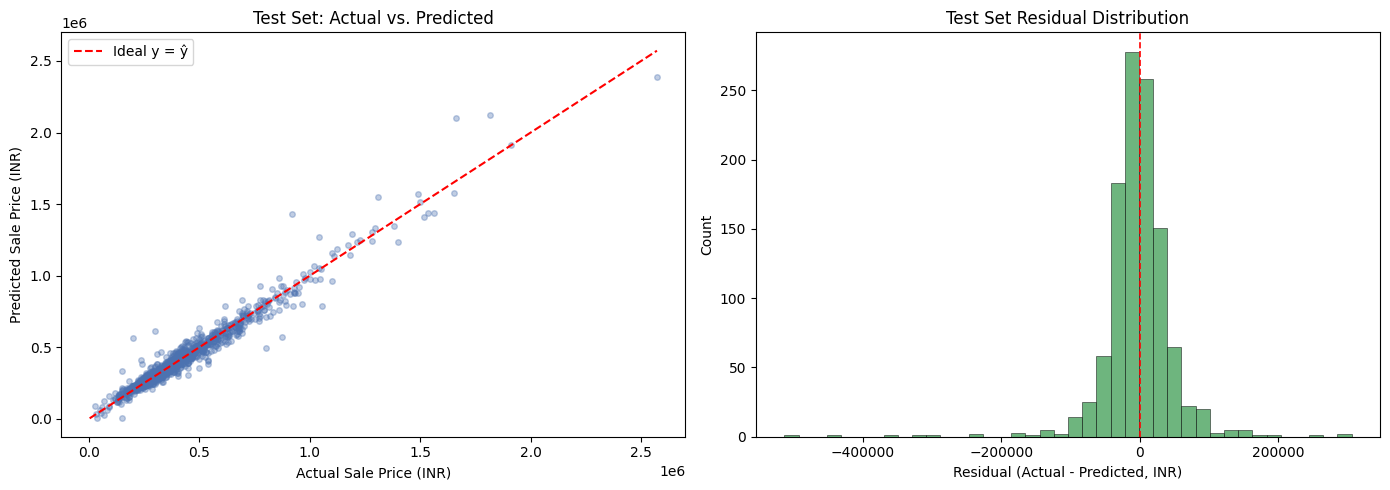

In [15]:
# ==============================================================================
# Cell 7: Test Set Error & Residual Diagnostics
# ==============================================================================

y_true_test = y_test.reshape(-1)
y_pred_test = test_pred_orig.reshape(-1)
residuals = y_true_test - y_pred_test
abs_errors = np.abs(residuals)

print("Absolute Error Summary (INR):")
print(pd.Series(abs_errors).describe(percentiles=[0.5, 0.75, 0.9, 0.95]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Actual vs Predicted sale_price
axes[0].scatter(y_true_test, y_pred_test, alpha=0.35, s=16, color="#4C72B0")
min_val = min(y_true_test.min(), y_pred_test.min())
max_val = max(y_true_test.max(), y_pred_test.max())
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1.5, label="Ideal y = ŷ")
axes[0].set_xlabel("Actual Sale Price (INR)")
axes[0].set_ylabel("Predicted Sale Price (INR)")
axes[0].set_title("Test Set: Actual vs. Predicted")
axes[0].legend()

# 2. Residual distribution
axes[1].hist(residuals, bins=40, color="#55A868", alpha=0.85, edgecolor="black", linewidth=0.4)
axes[1].axvline(0, color="red", linestyle="--", linewidth=1.2)
axes[1].set_xlabel("Residual (Actual - Predicted, INR)")
axes[1].set_ylabel("Count")
axes[1].set_title("Test Set Residual Distribution")

plt.tight_layout()
plt.show()

=== Test Set Model Comparison ===
                                    Model  Test MSE (INR²)  Test RMSE (INR)  Test MAE (INR)  Test R²
            Linear Regression (hidden=[]) 9,359,077,376.00        96,742.32       67,464.88     0.84
Final MLP ([64, 64, 64], adam, lr=0.0005) 2,591,808,000.00        50,909.80       31,009.36     0.96

Improvement over Linear Baseline -> MSE reduced by 72.31% | MAE reduced by 54.04%

=== Top 10 Largest Prediction Errors on Test Set ===
 Actual Price (INR)  Predicted Price (INR)  Residual (Actual - Pred)  Abs Error (INR)
         917,299.00           1,430,440.12               -513,141.12       513,141.12
       1,663,670.00           2,100,821.75               -437,151.75       437,151.75
         200,000.00             564,717.69               -364,717.69       364,717.69
         300,000.00             613,788.00               -313,788.00       313,788.00
         800,000.00             494,122.59                305,877.41       305,877.41
       1,8

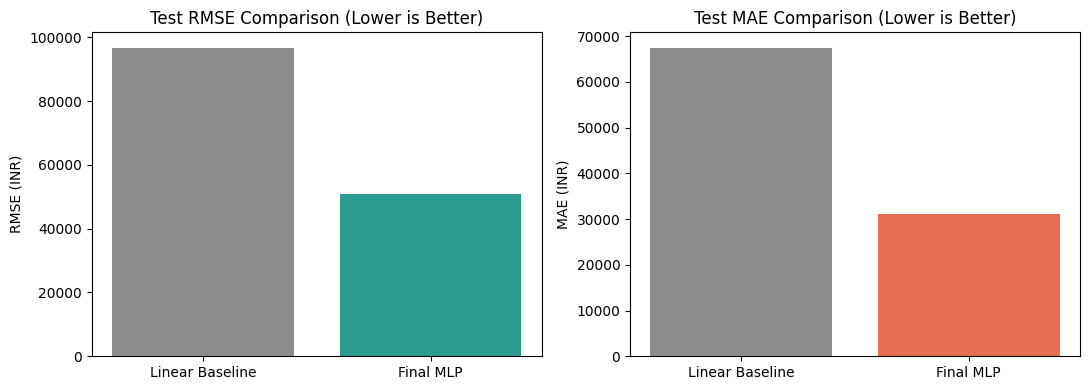

In [16]:
# ==============================================================================
# Cell 8: Linear Baseline vs. Final Neural Network Test Comparison & Top Errors
# ==============================================================================

# 1. Evaluate the linear regression baseline (hidden_dims=[]) on the test set
lin_model.cpu().eval()
with torch.no_grad():
    lin_test_pred_scaled = lin_model(torch.tensor(X_test)).numpy()
    lin_test_pred_orig = y_scaler.inverse_transform(lin_test_pred_scaled)

lin_test_mse = float(np.mean((y_test - lin_test_pred_orig) ** 2))
lin_test_rmse = float(np.sqrt(lin_test_mse))
lin_test_mae = float(mean_absolute_error(y_test, lin_test_pred_orig))
lin_test_r2 = float(r2_score(y_test, lin_test_pred_orig))

# 2. Build a clean side-by-side comparison table
comparison_df = pd.DataFrame([
    {
        "Model": "Linear Regression (hidden=[])",
        "Test MSE (INR²)": lin_test_mse,
        "Test RMSE (INR)": lin_test_rmse,
        "Test MAE (INR)": lin_test_mae,
        "Test R²": round(lin_test_r2, 4),
    },
    {
        "Model": f"Final MLP ({final_hidden}, {final_opt_name}, lr={final_lr})",
        "Test MSE (INR²)": test_mse,
        "Test RMSE (INR)": test_rmse,
        "Test MAE (INR)": test_mae,
        "Test R²": round(test_r2, 4),
    },
])

mse_improvement_pct = ((lin_test_mse - test_mse) / lin_test_mse) * 100.0
mae_improvement_pct = ((lin_test_mae - test_mae) / lin_test_mae) * 100.0

print("=== Test Set Model Comparison ===")
print(comparison_df.to_string(index=False))
print(
    f"\nImprovement over Linear Baseline -> "
    f"MSE reduced by {mse_improvement_pct:.2f}% | MAE reduced by {mae_improvement_pct:.2f}%"
)

# 3. Inspect the 10 largest absolute errors on the test set
error_table = pd.DataFrame({
    "Actual Price (INR)": y_true_test,
    "Predicted Price (INR)": y_pred_test,
    "Residual (Actual - Pred)": residuals,
    "Abs Error (INR)": abs_errors,
}).sort_values("Abs Error (INR)", ascending=False)

print("\n=== Top 10 Largest Prediction Errors on Test Set ===")
print(error_table.head(10).to_string(index=False))

# 4. Visual comparison of Test RMSE and Test MAE
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

model_names = ["Linear Baseline", "Final MLP"]
rmse_vals = [lin_test_rmse, test_rmse]
mae_vals = [lin_test_mae, test_mae]

axes[0].bar(model_names, rmse_vals, color=["#8C8C8C", "#2A9D8F"])
axes[0].set_title("Test RMSE Comparison (Lower is Better)")
axes[0].set_ylabel("RMSE (INR)")

axes[1].bar(model_names, mae_vals, color=["#8C8C8C", "#E76F51"])
axes[1].set_title("Test MAE Comparison (Lower is Better)")
axes[1].set_ylabel("MAE (INR)")

plt.tight_layout()
plt.show()

In [18]:
# ==============================================================================
# Cell 9: Automated Experimental Summary & Final Wrap-Up
# ==============================================================================

print("==================== FINAL EXPERIMENTAL WRAP-UP ====================\n")

# 1. Dataset & split recap
print(f"Dataset rows after cleaning: {len(df_clean):,} | Input features: {input_dim}")
print(f"Split sizes -> Train: {len(X_train):,} | Val: {len(X_val):,} | Test: {len(X_test):,}\n")

# 2. Best single-factor runs across the experiment suite
if "results_df" in globals():
    base_val = results_df.loc[results_df["Topic"] == "Baseline NN", "Val MSE"].iloc[0]
    best_overall = results_df.dropna(subset=["Val MSE"]).sort_values("Val MSE").iloc[0]
    nan_count = int(results_df["Val MSE"].isna().sum())

    print(f"Total experiments run: {len(results_df)} | Diverged/NaN runs: {nan_count}")
    print(f"Reference NN Baseline Val MSE: {base_val:,.0f}")
    print(
        f"Best single-factor run: Run {best_overall['Run']} "
        f"[{best_overall['Topic']} -> {best_overall['Setting']}] "
        f"with Val MSE = {best_overall['Val MSE']:,.0f}\n"
    )

# 3. Topic winners recap
if "summary_df" in globals():
    print("Topic-by-Topic Winners:")
    for _, row in summary_df.iterrows():
        print(
            f"  * {row['Topic']}: {row['Best Setting']} "
            f"(Val MSE: {row['Best Val MSE']:,.0f}, {row['% vs Baseline']:+.2f}% vs. baseline)"
        )
    print()

# 4. Final test set performance
if "test_mse" in globals():
    print(
        f"Final Model ({final_hidden}, {final_opt_name}, lr={final_lr}, bs={final_batch_size}, loss={final_loss_name}) "
        f"at Best Epoch {best_epoch}:"
    )
    print(f"  * Test MSE : {test_mse:,.0f}")
    print(f"  * Test RMSE: {test_rmse:,.2f} INR")
    print(f"  * Test MAE : {test_mae:,.2f} INR")
    print(f"  * Test R²  : {test_r2:.4f}")

if "lin_test_mse" in globals() and "test_mse" in globals():
    rel_gain = ((lin_test_mse - test_mse) / lin_test_mse) * 100.0
    print(f"  * Gain over Linear Regression ([]) Test MSE: {rel_gain:.2f}% reduction\n")

# 5. Practical experimental notes for your write-up
notes = [
    "High learning rates (e.g., lr=0.5) can cause training instability or NaN loss on scaled targets.",
    "Non-linear hidden layers capture car pricing interactions much better than plain linear regression ([]).",
    "Large errors on expensive outliers heavily influence MSE/RMSE compared to MAE.",
    "All final test metrics come from a single evaluation on X_test after selecting the best validation checkpoint.",
]
print("Key Experimental Takeaways:")
for n in notes:
    print(f"  - {n}")

==================== FINAL EXPERIMENTAL WRAP-UP ====================

Dataset rows after cleaning: 7,396 | Input features: 264
Split sizes -> Train: 5,177 | Val: 1,109 | Test: 1,110

Total experiments run: 32 | Diverged/NaN runs: 0
Reference NN Baseline Val MSE: 4,523,015,168
Best single-factor run: Run 3 [Learning rate -> lr = 0.0005] with Val MSE = 4,267,267,072

Topic-by-Topic Winners:
  * Baseline NN: Ref NN: [64,64,64], Adam, lr=0.003, bs=64, MSE (Val MSE: 4,523,015,168, +0.00% vs. baseline)
  * Learning rate: lr = 0.0005 (Val MSE: 4,267,267,072, -5.65% vs. baseline)
  * Optimizer: Adam (lr=0.003, 10 epochs) (Val MSE: 4,483,081,728, -0.88% vs. baseline)
  * Batch size: batch_size = 32 (Val MSE: 4,735,857,664, +4.71% vs. baseline)
  * Depth and width: hidden = [128, 128] (Val MSE: 4,439,500,800, -1.85% vs. baseline)
  * Loss function: MSELoss (lr=0.003, 15 epochs) (Val MSE: 4,495,953,920, -0.60% vs. baseline)

Final Model ([64, 64, 64], adam, lr=0.0005, bs=64, loss=mse) at Best Epo

## Experimental Discussion & Conclusion

### 1. Single-Factor Ablation Findings
- **Baseline Reference:** A 3-layer MLP (`[64, 64, 64]`) trained with Adam (`lr=0.003`), batch size `64`, and `MSELoss` served as the reference point (`y` standardized via `StandardScaler` during training and evaluated in original `sale_price` INR units).
- **Learning Rate:** Too small a learning rate converges slowly within a fixed epoch budget, whereas an overly large learning rate (such as `lr=0.5`) risks training instability or `NaN` loss.
- **Optimizer & Batch Size:** Changing one hyperparameter at a time isolates how update dynamics (`SGD`, `SGD + momentum`, `Adam`) and gradient noise/mini-batch size affect convergence speed and validation MSE.
- **Depth, Width & Loss Function:** Adjusting hidden layer structure (`[]` linear baseline vs. shallow/deep/wide MLPs) and loss functions (`MSELoss`, `L1Loss`, `HuberLoss`) shows trade-offs between fitting non-linear pricing patterns and handling skewed/high-priced used car listings.

### 2. Final Model & Test Set Evaluation
- After selecting the best-performing validation configuration and restoring the best validation checkpoint, the final model was evaluated **once** on the held-out test set (`X_test`, `y_test`) using **MSE**, **RMSE**, **MAE**, and **$R^2$**.
- Comparing the final MLP against the plain linear regression model (`hidden_dims=[]`) highlights the benefit of non-linear representations on tabular car attributes (`yr_mfr`, `kms_run`, fuel/body/transmission features, etc.).

### 3. Error Analysis & Limitations
- Residual and actual-vs.-predicted plots show that larger absolute errors tend to occur on high-priced outlier vehicles, which disproportionately raise squared error metrics (MSE/RMSE) relative to MAE.
- Future improvements could include log-transforming skewed price targets, tuning regularization/learning-rate schedules, or testing additional feature engineering without leaking test information.